## Final Evaluation

<h3> Import Libraries <h3/>

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib

### Import Classification Metrics

In [2]:
from sklearn.metrics import classification_report,ConfusionMatrixDisplay

<h3>Load Data<h3/>

In [4]:
final_model=joblib.load(r'../DATA/covertype/final_model.pkl')
pca_model=joblib.load(r'../DATA/covertype/pca_model.pkl')
scaler=joblib.load(r'../DATA/covertype/scaler.pkl')
x=pd.read_csv(r'../DATA/covertype/x.csv')
y=pd.read_csv(r'../DATA/covertype/y.csv').values.ravel()
x_test=pd.read_csv(r'../DATA/covertype/x_test.csv')
y_test=pd.read_csv(r'../DATA/covertype/y_test.csv').values.ravel()

## Final Prediction

<h3>Process Final Test Data</h3>

In [7]:
x_test_s=scaler.transform(x_test)
decomposed_x_test_data=pca_model.transform(x_test_s)

<h3> Final Prediction Result </h3>

In [8]:
final_preds=final_model.predict(decomposed_x_test_data)

In [9]:
print(classification_report(y_test,final_preds))

              precision    recall  f1-score   support

           1       0.95      0.93      0.94     31776
           2       0.94      0.96      0.95     42495
           3       0.92      0.94      0.93      5363
           4       0.89      0.77      0.82       412
           5       0.93      0.76      0.83      1424
           6       0.88      0.85      0.87      2605
           7       0.96      0.93      0.95      3077

    accuracy                           0.94     87152
   macro avg       0.92      0.88      0.90     87152
weighted avg       0.94      0.94      0.94     87152



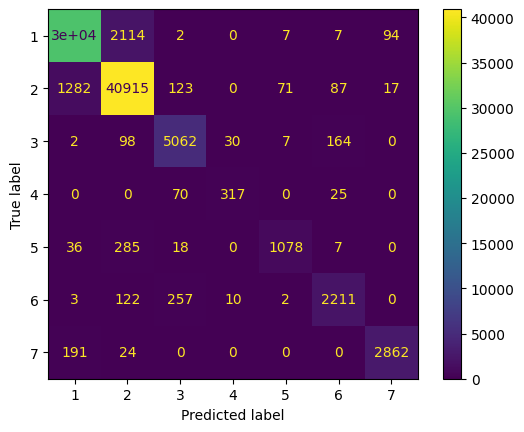

In [10]:
ConfusionMatrixDisplay.from_predictions(y_test,final_preds)

### Final Results and Conclusion

After evaluating and comparing multiple classical supervised machine learning algorithms, Random Forest was selected as the final model based on its superior performance during the experimental phase. The model was evaluated on the unseen test dataset and achieved an Accuracy of **94%** and a Macro F1-score of **90%**.

These results demonstrate that Random Forest provides strong predictive performance while maintaining a good balance across all seven forest cover types, including minority classes. The difference between Accuracy and Macro F1-score also highlights the importance of evaluating performance beyond overall accuracy, particularly in multiclass classification problems with imbalanced class distributions.

Overall, the experiments indicate that Random Forest is an effective and reliable choice for the Covertype classification task. Its strong performance with default hyperparameters also demonstrates that competitive results can be achieved without extensive computationally expensive optimization. This study highlights the effectiveness of classical machine learning algorithms and the importance of systematic model comparison, appropriate evaluation metrics, and computational efficiency.

## Final PipeLine Model

In [1]:
from sklearn.pipeline import make_pipeline

In [5]:
final_pip_model=make_pipeline([scaler,pca_model,final_model])
final_pip_model.fit(x,y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [6]:
joblib.dump(final_pip_model,r'../DATA/covertype/final_pip_model.pkl')

['../DATA/covertype/final_pip_model.pkl']